In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

Data loaded: (7043, 21)
Churn distribution: {0: 5163, 1: 1869}


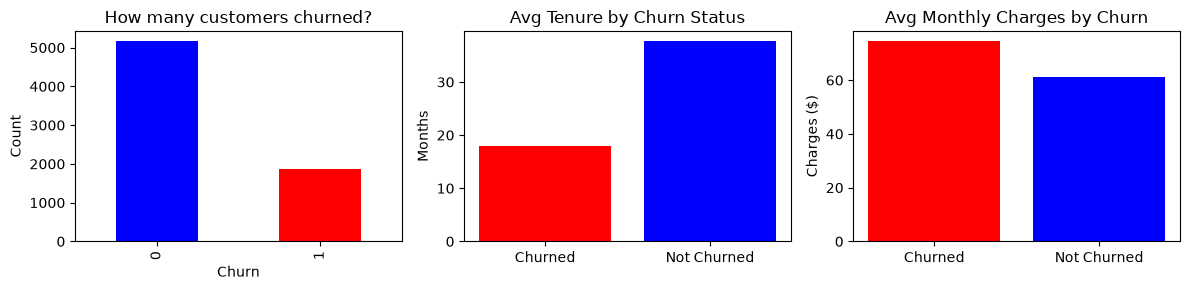

Observations:
- 26.6% customers churned
- Churned customers have lower tenure (avg 18 months)
- Churned customers have higher charges (avg $74)


In [2]:
# Load data
df = pd.read_csv('WA_Fn-UseC_-Telco-Customer-Churn.csv')
print("Data loaded:", df.shape)

# Fix TotalCharges (it has spaces, need to convert)
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'].astype(str).str.strip(),errors='coerce')
df = df.dropna(subset=['TotalCharges'])

# Convert Churn to 0 and 1
df['Churn'] = df['Churn'].apply(lambda x: 1 if x == 'Yes' else 0)

# Drop customerID (not needed)
df = df.drop(columns=['customerID'])

print(f"Churn distribution: {df['Churn'].value_counts().to_dict()}")

# Plot 1: Churn distribution
plt.figure(figsize=(12, 3))

plt.subplot(1, 3, 1)
df['Churn'].value_counts().plot(kind='bar', color=['blue', 'red'])
plt.title('How many customers churned?')
plt.ylabel('Count')

# Plot 2: Tenure vs Churn
plt.subplot(1, 3, 2)
churn_tenure = df[df['Churn'] == 1]['tenure'].mean()
no_churn_tenure = df[df['Churn'] == 0]['tenure'].mean()
plt.bar(['Churned', 'Not Churned'], [churn_tenure, no_churn_tenure], color=['red', 'blue'])
plt.title('Avg Tenure by Churn Status')
plt.ylabel('Months')

# Plot 3: Monthly Charges
plt.subplot(1, 3, 3)
churn_charges = df[df['Churn'] == 1]['MonthlyCharges'].mean()
no_churn_charges = df[df['Churn'] == 0]['MonthlyCharges'].mean()
plt.bar(['Churned', 'Not Churned'], [churn_charges, no_churn_charges], color=['red', 'blue'])
plt.title('Avg Monthly Charges by Churn')
plt.ylabel('Charges ($)')

plt.tight_layout()
plt.savefig('eda_plots.png')
plt.show()

print("Observations:")
print(f"- {(df['Churn'].sum() / len(df) * 100):.1f}% customers churned")
print(f"- Churned customers have lower tenure (avg {churn_tenure:.0f} months)")
print(f"- Churned customers have higher charges (avg ${churn_charges:.0f})")

In [3]:
# Separate features and target
X = df.drop(columns=['Churn'])
y = df['Churn'].values.astype(int)

# Split data into training and testing sets
X_train_raw, X_test_raw, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)

# Encode categorical features separately
X_train = pd.get_dummies(X_train_raw, drop_first=True)
X_test = pd.get_dummies(X_test_raw, drop_first=True)

# Make sure both datasets have the same features
X_test = X_test.reindex(columns=X_train.columns,fill_value=0)

# Save feature names for future use
feature_columns = X_train.columns.tolist()

# Scale features
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print(f"Training samples: {X_train.shape[0]}")
print(f"Test samples: {X_test.shape[0]}")
print(f"Number of features: {X_train.shape[1]}")

Training samples: 5625
Test samples: 1407
Number of features: 30


In [4]:
# Building logistic regression from scratch
class SimpleLogisticRegression:
    
    def __init__(self, learning_rate=0.01, iterations=500):
        self.lr = learning_rate
        self.iterations = iterations
        self.weights = None
        self.bias = None
    
    def sigmoid(self, z):
        # Sigmoid function converts any number to 0-1 range
        # Formula: 1 / (1 + e^(-z))
        return 1 / (1 + np.exp(-np.clip(z, -500, 500)))
    
    def fit(self, X, y):
        n_samples, n_features = X.shape
        
        # Start with zero weights and bias
        self.weights = np.zeros(n_features)
        self.bias = 0
        
        # Gradient descent - update weights iteratively
        for iteration in range(self.iterations):
            
            # Step 1: Predict
            z = np.dot(X, self.weights) + self.bias
            predictions = self.sigmoid(z)
            
            # Step 2: Calculate error
            error = predictions - y
            
            # Step 3: Calculate gradients
            dw = (np.dot(X.T, error)) / n_samples
            db = np.sum(error) / n_samples
            
            # Step 4: Update weights and bias
            self.weights -= self.lr * dw
            self.bias -= self.lr * db
            
            # Print progress
            if (iteration + 1) % 100 == 0:
                loss = -np.mean(y * np.log(predictions + 1e-9) + 
                               (1 - y) * np.log(1 - predictions + 1e-9))
                print(f"Iteration {iteration + 1}, Loss: {loss:.4f}")
    
    def predict(self, X):
        z = np.dot(X, self.weights) + self.bias
        predictions = self.sigmoid(z)
        return (predictions >= 0.5).astype(int)
    
    def predict_proba(self, X):
        z = np.dot(X, self.weights) + self.bias
        return self.sigmoid(z)

print("Custom Logistic Regression class created!")

Custom Logistic Regression class created!


In [5]:
# Create and train the model
print("Training custom model...\n")
model = SimpleLogisticRegression(learning_rate=0.1, iterations=500)
model.fit(X_train, y_train)
print("\nTraining complete!")

# Make predictions
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)

Training custom model...

Iteration 100, Loss: 0.4303
Iteration 200, Loss: 0.4186
Iteration 300, Loss: 0.4160
Iteration 400, Loss: 0.4150
Iteration 500, Loss: 0.4145

Training complete!


In [6]:
# Calculate metrics manually
correct = np.sum(y_pred == y_test)
accuracy = correct / len(y_test)

# Confusion matrix elements
tp = np.sum((y_pred == 1) & (y_test == 1))  # True Positives
fp = np.sum((y_pred == 1) & (y_test == 0))  # False Positives
fn = np.sum((y_pred == 0) & (y_test == 1))  # False Negatives
tn = np.sum((y_pred == 0) & (y_test == 0))  # True Negatives

# Calculate performance metrics
precision = tp / (tp + fp) if (tp + fp) > 0 else 0
recall = tp / (tp + fn) if (tp + fn) > 0 else 0
f1 = 2 * (precision * recall) / (precision + recall) if (precision + recall) > 0 else 0

print("="*50)
print("CUSTOM LOGISTIC REGRESSION - RESULTS")
print("="*50)
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-Score:  {f1:.4f}")

print("\nConfusion Matrix:")
print(f"True Negatives:  {tn}")
print(f"False Positives: {fp}")
print(f"False Negatives: {fn}")
print(f"True Positives:  {tp}")

roc_auc = roc_auc_score(y_test, y_prob)

print("\nAdditional Evaluation Metrics")
print("-" * 35)
print(f"ROC-AUC: {roc_auc:.4f}")

print("\nDetailed Classification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=['No Churn', 'Churn'],
        zero_division=0
    )
)

CUSTOM LOGISTIC REGRESSION - RESULTS
Accuracy:  0.7982
Precision: 0.6347
Recall:    0.5668
F1-Score:  0.5989

Confusion Matrix:
True Negatives:  911
False Positives: 122
False Negatives: 162
True Positives:  212

Additional Evaluation Metrics
-----------------------------------
ROC-AUC: 0.8325

Detailed Classification Report:
              precision    recall  f1-score   support

    No Churn       0.85      0.88      0.87      1033
       Churn       0.63      0.57      0.60       374

    accuracy                           0.80      1407
   macro avg       0.74      0.72      0.73      1407
weighted avg       0.79      0.80      0.79      1407



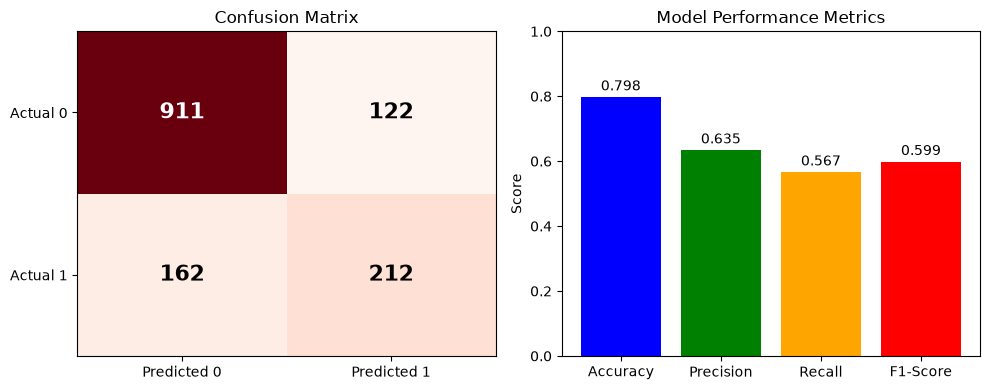

In [7]:
# Plot 1: Confusion Matrix
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
cm = np.array([[tn, fp], [fn, tp]])
plt.imshow(cm, cmap='Reds', aspect='auto')
for i in range(2):
    for j in range(2):
        plt.text(j, i, str(cm[i, j]), ha='center', va='center', 
                color='white' if cm[i, j] > cm.max() / 2 else 'black', fontsize=16, fontweight='bold')
plt.xticks([0, 1], ['Predicted 0', 'Predicted 1'])
plt.yticks([0, 1], ['Actual 0', 'Actual 1'])
plt.title('Confusion Matrix')

# Plot 2: Metrics Comparison
plt.subplot(1, 2, 2)
metrics = ['Accuracy', 'Precision', 'Recall', 'F1-Score']
scores = [accuracy, precision, recall, f1]
plt.bar(metrics, scores, color=['blue', 'green', 'orange', 'red'])
plt.ylim([0, 1])
plt.ylabel('Score')
plt.title('Model Performance Metrics')
for i, v in enumerate(scores):
    plt.text(i, v + 0.02, f'{v:.3f}', ha='center')

plt.tight_layout()
plt.savefig('results.png', dpi=100)
plt.show()

In [8]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Train sklearn model
sklearn_model = LogisticRegression(max_iter=1000, random_state=42)
sklearn_model.fit(X_train, y_train)
y_pred_sklearn = sklearn_model.predict(X_test)
y_prob_sklearn = sklearn_model.predict_proba(X_test)[:, 1]
sklearn_roc_auc = roc_auc_score(y_test,y_prob_sklearn)

# Compare
sklearn_acc = accuracy_score(y_test, y_pred_sklearn)
sklearn_prec = precision_score(y_test, y_pred_sklearn)
sklearn_rec = recall_score(y_test, y_pred_sklearn)
sklearn_f1 = f1_score(y_test, y_pred_sklearn)

print("\n" + "=" * 65)
print("CUSTOM VS SCIKIT-LEARN LOGISTIC REGRESSION")
print("=" * 65)
results = pd.DataFrame({
    'Metric': [
        'Accuracy',
        'Precision',
        'Recall',
        'F1-Score',
        'ROC-AUC'
    ],
    'Custom LR': [
        accuracy,
        precision,
        recall,
        f1,
        roc_auc
    ],
    'Scikit-learn LR': [
        sklearn_acc,
        sklearn_prec,
        sklearn_rec,
        sklearn_f1,
        sklearn_roc_auc
    ]
})

print(results.round(4).to_string(index=False))


CUSTOM VS SCIKIT-LEARN LOGISTIC REGRESSION
   Metric  Custom LR  Scikit-learn LR
 Accuracy     0.7982           0.8038
Precision     0.6347           0.6476
   Recall     0.5668           0.5749
 F1-Score     0.5989           0.6091
  ROC-AUC     0.8325           0.8357
